[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/08-modelling.ipynb)

# Modelling

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Compare model families fairly on the same data, split and yardstick.</li>
<li>Read an overfitting gap and recognise overconfident probabilities.</li>
<li>Use a reliability diagram and a learning curve to decide where improvement must come from.</li>
<li>Choose the simplest model within noise of the best, with paired evidence.</li>
</ul>
</div>

**Prerequisites:** <a href="../07-features/">Feature Engineering</a>. **Dataset:** Online Retail II. **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

We have a bar to beat (the baselines), a split we trust, and a feature table. Now the question every course eventually reaches: **which model?** The honest way to answer is to give every candidate the same data, the same split and the same yardstick, and to look at more than one number: how well it ranks, how *trustworthy its probabilities* are (our value-at-risk rule multiplies them by money, so a probability of 0.9 had better mean 90%), how badly it overfits, and what it costs to run.

We compare five candidates:

| Candidate | Why it is here |
|---|---|
| **Logistic regression** | simple, fast, interpretable: the benchmark that must be beaten to justify anything fancier |
| **Decision tree, unlimited depth** | the textbook overfitter, as a warning |
| **Decision tree, depth 4** | a tree that cannot memorise: readable rules |
| **Random forest** | many de-correlated trees, averaged |
| **Gradient boosting** | trees built one after another, each correcting the last |

## Different families need different preparation

Tree models only compare orders, so they take the features as they are and handle missing values natively. A linear model assumes a roughly linear, well-scaled input, so it needs the heavy tails (Page 4), missing values and the broken ratio (Page 7) handled **inside its pipeline**, so that every fit learns its medians and scales from the training rows only.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from mlp_data.metrics import at_risk_report, bootstrap_difference

cleaned = retail.clean_retail(load_retail())
sp = retail.build_splits(cleaned.sales, cleaned.returns, features="full")
train, valid = sp.train, sp.valid
FEATURES = [c for c in train.columns if c not in ("customer_id", "cutoff", "y")]

log1p = FunctionTransformer(np.log1p)
signed_log = FunctionTransformer(lambda x: np.sign(x) * np.log1p(np.abs(x)))
capped_log = FunctionTransformer(lambda x: np.log1p(np.clip(x, 0, 50)))      # the overdue ratio can explode: cap, then log

heavy_tailed = ["recency_days", "frequency", "monetary", "monetary_90d", "avg_order_value", "items_per_order", "n_products",
                "freq_30d", "freq_90d", "freq_180d", "freq_prev_90d", "n_returns", "tenure_days", "avg_gap_days"]
other = [c for c in FEATURES if c not in heavy_tailed + ["recency_over_gap", "trend_90d"]]

prepare_for_linear = ColumnTransformer([
    ("tails",  make_pipeline(SimpleImputer(strategy="median", add_indicator=True), log1p, StandardScaler()), heavy_tailed),
    ("ratio",  make_pipeline(SimpleImputer(strategy="median", add_indicator=True), capped_log, StandardScaler()), ["recency_over_gap"]),
    ("change", make_pipeline(signed_log, StandardScaler()), ["trend_90d"]),
    ("rest",   StandardScaler(), other),
])
print(f"{len(FEATURES)} features: {len(heavy_tailed)} heavy-tailed (log), 1 exploding ratio (cap, log), 1 signed change, {len(other)} left as they are")

18 features: 14 heavy-tailed (log), 1 exploding ratio (cap, log), 1 signed change, 2 left as they are


In [3]:
import time

def tree_input(df):                       # scikit-learn trees need a number in every cell; -1 is outside every real value here
    return df[FEATURES].fillna(-1)

candidates = {
    "logistic regression":    (make_pipeline(prepare_for_linear, LogisticRegression(max_iter=2000)), lambda d: d[FEATURES]),
    "tree, unlimited depth":  (DecisionTreeClassifier(random_state=0), tree_input),
    "tree, depth 4":          (DecisionTreeClassifier(max_depth=4, random_state=0), tree_input),
    "random forest":          (RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=0), tree_input),
    "gradient boosting":      (HistGradientBoostingClassifier(max_iter=150, learning_rate=0.06, max_leaf_nodes=15, min_samples_leaf=40,
                                                              l2_regularization=1.0, random_state=0), lambda d: d[FEATURES]),
}
fitted, probs, rows = {}, {}, {}
for name, (model, prep) in candidates.items():
    t0 = time.perf_counter(); model.fit(prep(train), train["y"]); seconds = time.perf_counter() - t0
    p = model.predict_proba(prep(valid))[:, 1]
    fitted[name], probs[name] = model, p
    quality = at_risk_report(valid["y"], p, valid["monetary"], probabilities=True)
    money = at_risk_report(valid["y"], p, valid["monetary"], risk=(1 - p) * valid["monetary"], probabilities=True)
    rows[name] = {"train AUC": roc_auc_score(train["y"], model.predict_proba(prep(train))[:, 1]), "validation AUC": quality["AUC"],
                  "Brier": quality["brier"], "log loss": quality["log loss"],
                  "revenue@200 % of oracle": money["revenue@200 % of oracle"], "fit seconds": seconds}
results = pd.DataFrame(rows).T
results["overfit gap"] = results["train AUC"] - results["validation AUC"]
results.assign(**{c: results[c].map("{:.3f}".format) for c in ["train AUC", "validation AUC", "overfit gap", "Brier", "log loss"]},
               **{"revenue@200 % of oracle": results["revenue@200 % of oracle"].map("{:.1%}".format), "fit seconds": results["fit seconds"].map("{:.2f}".format)})

,train AUC,validation AUC,Brier,log loss,revenue@200 % of oracle,fit seconds,overfit gap
logistic regression,0.785,0.796,0.172,0.520,65.7%,0.07,-0.011
"tree, unlimited depth",1.000,0.634,0.330,4.559,51.5%,0.13,0.366
"tree, depth 4",0.784,0.784,0.174,0.526,59.4%,0.04,-0.000
random forest,0.886,0.797,0.169,0.513,65.7%,1.13,0.089
gradient boosting,0.845,0.800,0.169,0.511,68.5%,0.85,0.044


In [4]:
# The later pages import these two models from mlp_data.models. Confirm they are the same models we just built by hand.
from mlp_data import models

lr = models.make_logistic().fit(train[models.FEATURES], train["y"])
assert np.allclose(lr.predict_proba(valid[models.FEATURES])[:, 1], probs["logistic regression"], atol=1e-6)
gb = models.make_boosting().fit(train[models.FEATURES], train["y"])
assert abs(roc_auc_score(valid["y"], gb.predict_proba(valid[models.FEATURES])[:, 1]) - results.loc["gradient boosting", "validation AUC"]) < 1e-3
print("mlp_data.models reproduces the logistic regression exactly and the boosted model to three decimals")

mlp_data.models reproduces the logistic regression exactly and the boosted model to three decimals


**Reading the table.**

- **Logistic regression, forest and boosting land within 0.004 AUC of each other**, and even the depth-4 tree is only about 0.015 behind. A plain linear model is nearly indistinguishable from boosted trees at ranking. This is the same message as the feature page: we are near what these inputs can support, and a fancier algorithm cannot create information that is not there.
- **The unlimited tree is a disaster, and a useful one.** It scores a *perfect* 1.000 on the data it trained on and far worse on validation. It has memorised the training rows. Its **log loss is huge** because it makes confident wrong predictions (it says 0% or 100% when the truth is in between). A model that is overconfident is dangerous precisely when you multiply its probability by money.
- **"Overfit gap"** (train minus validation AUC) is the number to watch. The forest's gap (about 0.09) is twice boosting's (about 0.04); the logistic regression and the shallow tree have none (a slightly negative gap simply means validation scored a little higher than training, which can happen when periods differ in difficulty).
- **Cost is not equal.** The logistic regression fits in a fraction of a second; the forest takes far longer, for no gain in AUC.

## Watching overfitting happen

Let a tree grow deeper one level at a time, and track both scores.

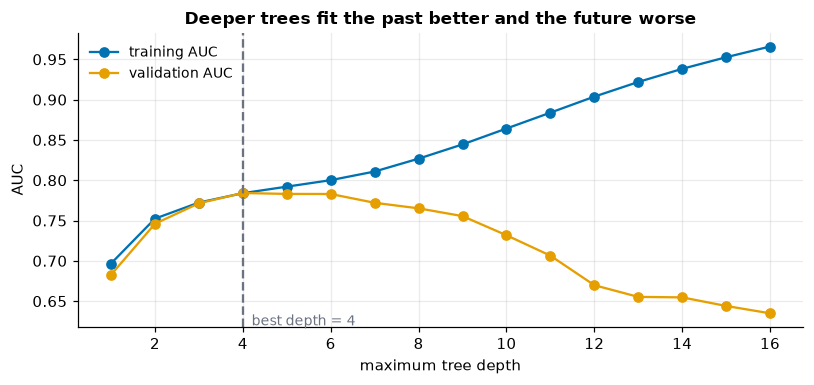

In [5]:
depths = list(range(1, 17))
curve = []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(tree_input(train), train["y"])
    curve.append((roc_auc_score(train["y"], t.predict_proba(tree_input(train))[:, 1]), roc_auc_score(valid["y"], t.predict_proba(tree_input(valid))[:, 1])))
curve = pd.DataFrame(curve, index=depths, columns=["train", "validation"])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(curve.index, curve["train"], marker="o", color=style.BLUE, label="training AUC")
ax.plot(curve.index, curve["validation"], marker="o", color=style.ORANGE, label="validation AUC")
best = int(curve["validation"].idxmax())
ax.axvline(best, color=style.GREY, ls="--"); ax.text(best + 0.2, 0.62, f"best depth = {best}", fontsize=9, color=style.GREY)
ax.set(xlabel="maximum tree depth", ylabel="AUC", title="Deeper trees fit the past better and the future worse"); ax.legend()
plt.tight_layout(); plt.show()
assert curve["train"].iloc[-1] > curve["train"].iloc[3] and curve["validation"].iloc[-1] < curve["validation"].max() - 0.05

**Reading the chart.** Training AUC rises steadily with depth, because a deeper tree can carve out ever finer pockets of the training rows. Validation AUC rises at first (the tree is learning real structure), peaks at a shallow depth, and then **falls**: from there on the tree is memorising noise. The gap between the two lines *is* overfitting. The remedy is not a cleverer algorithm but **constraints**: limit depth, require a minimum number of rows per leaf, or average many trees. That is exactly what the forest and boosting do.

## Can we trust the probabilities?

Our decision multiplies a probability by money, so we need probabilities that *mean* what they say. A **reliability diagram** groups customers by predicted probability and compares it with how often they actually returned. A trustworthy model hugs the diagonal.

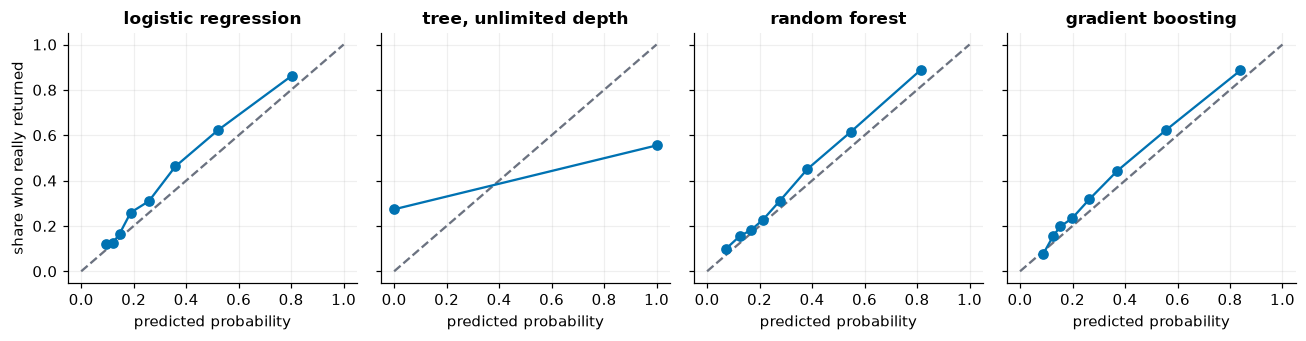

In [6]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharex=True, sharey=True)
for ax, name in zip(axes, ["logistic regression", "tree, unlimited depth", "random forest", "gradient boosting"]):
    observed, predicted = calibration_curve(valid["y"], probs[name], n_bins=8, strategy="quantile")
    ax.plot([0, 1], [0, 1], color=style.GREY, ls="--"); ax.plot(predicted, observed, marker="o", color=style.BLUE)
    ax.set(title=name, xlabel="predicted probability"); ax.grid(alpha=0.2)
axes[0].set_ylabel("share who really returned")
plt.tight_layout(); plt.show()

**Reading the diagrams.** The three sensible models follow the diagonal, with a mild and consistent tilt: they **under-predict**, so customers they score at 50% to 55% actually return nearer 60%. That is what you would expect when the validation period has a higher repurchase rate than the training period (36.6% against 34.4%), and it is an early taste of the drift problem. The unlimited tree only ever says about 0% or 100%, so its middle is empty, and both of its extremes are wrong: customers it gives 0% return about 27% of the time, and those it gives 100% only about 55%. That is why its log loss was so bad. If a model's probabilities are off, a calibration step (fit on data the model has not seen) can repair them, but it is better to start with a model that is already honest.

## Would more data help?

A **learning curve** answers a practical question: if we collected twice the customers, would the model improve? Train on growing slices of the training customers and watch validation AUC.

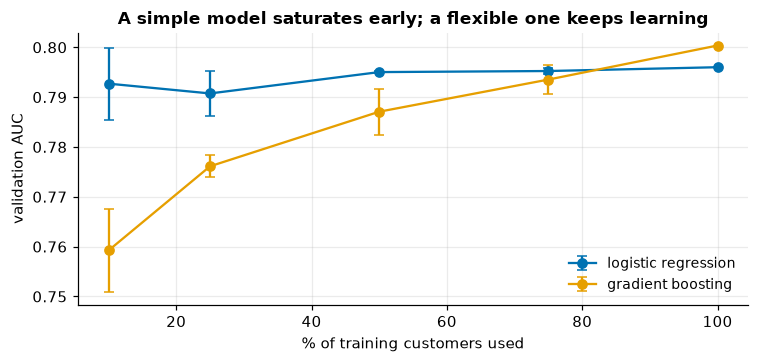

In [7]:
rng = np.random.default_rng(0)
customers = train["customer_id"].unique()
points = []
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    for rep in range(3):
        chosen = rng.choice(customers, int(len(customers) * frac), replace=False)
        sub = train[train["customer_id"].isin(chosen)]
        for name in ["logistic regression", "gradient boosting"]:
            model = clone(candidates[name][0]).fit(candidates[name][1](sub), sub["y"])
            points.append((frac, name, roc_auc_score(valid["y"], model.predict_proba(candidates[name][1](valid))[:, 1])))
lc = pd.DataFrame(points, columns=["share of training customers", "model", "validation AUC"]).groupby(["share of training customers", "model"])["validation AUC"].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(7, 3.4))
for (name, color) in [("logistic regression", style.BLUE), ("gradient boosting", style.ORANGE)]:
    d = lc[lc["model"] == name]
    ax.errorbar(d["share of training customers"] * 100, d["mean"], yerr=d["std"], marker="o", color=color, capsize=3, label=name)
ax.set(xlabel="% of training customers used", ylabel="validation AUC", title="A simple model saturates early; a flexible one keeps learning"); ax.legend()
plt.tight_layout(); plt.show()

**Reading the curve.** The two models behave very differently. **Logistic regression is already at its ceiling with a tenth of the customers**: more rows add nothing, because a handful of coefficients are learned quickly. **Boosting starts far lower and climbs steadily**, drawing level at about 80% of the data and only just ahead at 100%, with the curve not yet fully flat. A flexible model needs more data to find its structure; a simple one saturates early. Two lessons: with a smaller dataset, the simple model would win outright; and with these features the best either can do is close to 0.80 AUC, so the next real gains must come from better *information* (new features, new data sources) or a better question, not from a fancier algorithm.

## Is the apparent winner really better?

Boosting is nominally first. Paired bootstrap against the simple logistic regression, on the same validation customers:

In [8]:
v = valid["monetary"].to_numpy()
p_gb, p_lr, p_rf = probs["gradient boosting"], probs["logistic regression"], probs["random forest"]
rows_cmp = {}
for label, (pa, pb) in {"boosting vs logistic": (p_gb, p_lr), "forest vs logistic": (p_rf, p_lr), "boosting vs forest": (p_gb, p_rf)}.items():
    auc = bootstrap_difference(valid["y"], v, 1 - pa, 1 - pb, metric="AUC", n_boot=200, seed=0)
    rev = bootstrap_difference(valid["y"], v, (1 - pa) * v, (1 - pb) * v, metric="revenue@200", n_boot=200, seed=0)
    rows_cmp[label] = {"AUC difference": f"{auc['mean']:+.4f}  [{auc['low']:+.4f}, {auc['high']:+.4f}]",
                       "revenue@200 difference": f"{rev['mean']:+,.0f}  [{rev['low']:+,.0f}, {rev['high']:+,.0f}]",
                       "first is better in (revenue)": f"{rev['share_a_better']:.0%}"}
pd.DataFrame(rows_cmp).T

,AUC difference,revenue@200 difference,first is better in (revenue)
boosting vs logistic,"+0.0042 [-0.0015, +0.0096]","+22,741 [-6,763, +48,497]",90%
forest vs logistic,"+0.0008 [-0.0045, +0.0069]","-1,982 [-25,374, +21,580]",48%
boosting vs forest,"+0.0035 [-0.0005, +0.0071]","+24,723 [+3,846, +45,402]",96%


**Reading the comparison.**

- **Boosting vs logistic regression:** boosting has the higher point estimates, but the 90% interval for the AUC difference (about −0.002 to +0.010) *and* for the revenue difference (about −£7k to +£48k) both include zero. We cannot claim it is better.
- **Forest vs logistic regression:** indistinguishable.
- **Boosting vs forest:** boosting is ahead on revenue in nearly every resample (96%), with an interval above zero, so it beats the forest. The forest is also about seventeen times slower to fit than the logistic regression, for no gain.

## Our choice

We apply the rule from the check-yourself box: **prefer the simplest model whose performance is within noise of the best.** That makes the **logistic regression our champion**: it is as good as anything at ranking, well behaved on probabilities, has no overfit gap, fits instantly, and can be explained to a non-specialist.

We keep **gradient boosting as the challenger**. It has the best point estimates, the learning curve says it is still gaining from more data, and it is the model most likely to improve with tuning. The next page tunes both fairly and settles it with the same paired test.

<div class="admonition note">
<p class="admonition-title">A decision made on validation is a small bet, not a verdict</p>
<p>We have now compared several models on the validation set. With only a handful of candidates the optimism from "picking the winner" is small, but it is not zero, and it grows with every extra model and setting we try. That is exactly why the <strong>test set</strong> stays locked until the very end: it is the only number not touched by our choices.</p>
</div>

## Check yourself

<details class="question">
<summary>1. The unlimited tree scores 1.000 on training data. Why is that a warning and not good news?</summary>

A score on the data the model learned from only measures memory. A tree grown until every leaf is pure has simply stored the training rows, noise included. The score that matters is on data the model has not seen, where it collapses. The gap between the two *is* overfitting.

</details>

<details class="question">
<summary>2. Why did we put the log transforms, imputers and scalers inside the logistic regression's pipeline instead of transforming the whole table first?</summary>

Because those steps *learn* from data (medians, means, standard deviations). Fitting them on the whole table would leak validation information into training. Inside a pipeline they are fitted on the training rows only, then applied unchanged to validation, exactly as they will be in production.

</details>

<details class="question">
<summary>3. Four models score almost the same. How should you choose between them?</summary>

Prefer the **simplest** model whose performance is within the noise of the best, unless the extra performance is large enough, on the metric that matters, to justify its costs (speed, maintenance, explainability). Report the comparison with intervals so the choice is defensible.

</details>

## Exercise

<details class="question">
<summary>Refit the random forest with <code>min_samples_leaf=1</code> instead of 20. Predict whether the overfit gap grows or shrinks, then check.</summary>

```python
rf1 = RandomForestClassifier(n_estimators=300, min_samples_leaf=1, n_jobs=-1, random_state=0).fit(tree_input(train), train["y"])
print("train AUC     :", round(roc_auc_score(train["y"], rf1.predict_proba(tree_input(train))[:, 1]), 3))
print("validation AUC:", round(roc_auc_score(valid["y"], rf1.predict_proba(tree_input(valid))[:, 1]), 3))
```

The training AUC reaches 1.000 (each tree can now memorise its rows) while validation AUC actually **drops**, from about 0.797 to about 0.775, so the gap grows from roughly 0.09 to over 0.22. `min_samples_leaf` is a dial between memorising and generalising; a larger value forces each leaf to summarise many customers, which is a form of regularisation.

</details>

## Recap

- Compare candidates on the **same** data, split and yardstick, and read more than one column: validation score, overfit gap, probability quality, cost.
- Different families need different preparation. Put anything that *learns from data* inside the pipeline.
- Overfitting is a gap between training and validation. It grows with model freedom, and the cure is **constraint**, not cleverness.
- Probabilities that feed a money calculation must be **calibrated**; check with a reliability diagram.
- A learning curve tells you whether more data or better information is the bottleneck.
- Choose the simplest model that is within noise of the best, and back the choice with paired intervals.

**Next:** *Evaluation and error analysis*, where we look beyond the headline number to where the chosen model is right, wrong, and unfair to certain customers.